In [2]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

C:\Users\M16\AppData\Local\Temp\ipykernel_16604\924501044.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")


from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [6]:
class AgentState(MessagesState):
    next_agent:str

In [10]:
@tool
def search_web(query: str) -> str:
    """Searich the web for information. """
    # Using Tavily for web search
    search = TavilySearchResults(max_results=3)
    results = search.invoke(query)
    return str(results)


In [12]:
@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content. """
    # Simple summary generation
    summary = f"Summary of findings :\n\n{content[:500]} ... "
    return summary

In [13]:
from langchain.chat_models import init_chat_model
llm=init_chat_model("groq:qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, client=<groq.resources.chat.completions.Completions object at 0x000002129AA31E90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002129ACF53D0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [28]:
# Define agent functions (simpler approach)
def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""

    messages = state["messages"]

    # Add system message for context
    system_msg = SystemMessage(content="You are a research assistant. Use the search_web tool to find  information about the user's request.")

    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + messages)

    # Return the response and route to writer
    return {
        "messages": [response],
        "next_agent": "writer"
    }

In [29]:
def writer_agent(state: AgentState):
    """Writer agent that creates summaries"""

    messages = state["messages"]

    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and creeate a clear, concise summary of the findings.")

    # Simple completion without tools
    response = llm.invoke([system_msg] + messages)

    return{
        "messages": [response],
        "next_agent": "end"}

In [30]:
def execute_tools(state: AgentState):
    """Execute any pending tool calls"""
    messages = state["messages"]
    last_message = messages[-1]

    # Check if there are tool calls to execute
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
    # Create tool node and execute
        tool_node = ToolNode([search_web, write_summary])
        response = tool_node.invoke(state)
        return response
# No tools to execute
    
    return state

In [ ]:
def create_minimal_multi_agent():
    """Minimal multi-agent system using just LLM calls"""

    def researcher_node(state: MessagesState):
    """Simple researcher using just LLM"""
    messages = state["messages"]

    # Create prompt for researcher
    prompt =[
    SystemMessage(content="You are a researcher. Analyze the user's question and")
    *messages

    ]
    # Get response
    response = llm.invoke(prompt)

    return {"messages": [response]}

 def writer_node(state: MessagesState):
    """Simple writer using just LLM"""
    messages = state["messages"]

    # Create prompt for writer
    prompt = [
    SystemMessage(content="You are a writer. Based on the research provided, create")
    ]

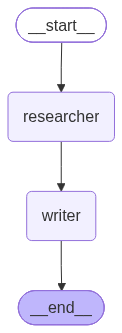

In [31]:
# Build graph
workflow = StateGraph(MessagesState)

# Add nodes
workflow.add_node("researcher", researcher_agent)
workflow.add_node("writer", writer_agent)

# Define flow
workflow.set_entry_point("researcher")
workflow.add_edge("researcher", "writer")
workflow.add_edge("writer", END)
final_workflow=workflow.compile()
final_workflow


In [ ]:
final_workflow.invoke({
    "messages": [
        HumanMessage(
            content="Research about the use case of agentic AI in business"
        )
    ]
})

{'messages': [HumanMessage(content='Research about the use case of agentic AI in business', additional_kwargs={}, response_metadata={}, id='8a895219-28ed-4c8f-b395-d0da9bc7a8f4'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 't30xy46f2', 'function': {'arguments': '{"query":"agentic AI use cases in business 2024 2025"}', 'name': 'search_web'}, 'type': 'function'}, {'id': 'qhwh4c17q', 'function': {'arguments': '{"query":"enterprise agentic AI applications benefits challenges"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 72, 'prompt_tokens': 304, 'total_tokens': 376, 'completion_time': 0.236164069, 'completion_tokens_details': None, 'prompt_time': 0.025117264, 'prompt_tokens_details': None, 'queue_time': 0.021224262, 'total_time': 0.261281333}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_43dd1ea4ee', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider':

: 

SUPERVIE Multi ai agent architucture

In [12]:
from typing import TypedDict, Annotated, List, Literal, Dict, Any
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
import random
from datetime import datetime
from langchain_core.prompts import ChatPromptTemplate

In [56]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=300
)

In [57]:
class SupervisorState(MessagesState):
    """State for the multi-agent system"""
    next_agent: str = ""
    research_data: str = ""
    analysis: str = ""
    final_report: str =""
    task_complete: bool = False
    current_task: str = ""


In [58]:

from langchain_core.prompts import ChatPromptTemplate

def create_supervisor_chain():
    """Creates the supervisor decision chain"""

    supervisor_prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a supervisor managing a team of agents:

        1. Researcher - Gathers information and data
        2. Analyst - Analyzes data and provides insights
        3. Writer - Creates reports and summaries

        Based on the current state and conversation, decide which agent should work next.
        If the task is complete, respond with DONE.

        Current state:
        - Has research data: {has_research}
        - Has analysis: {has_analysis}
        - Has report: {has_report}

        Respond with ONLY the agent name (researcher/analyst/writer) or DONE"""),

        ("human", "{task}")
    ])

    return supervisor_prompt | llm

In [59]:
def supervisor_agent(state: SupervisorState) -> Dict:
    """Supervisor decides next agent using Groq LLM"""

    messages = state["messages"]
    task = messages[-1].content if messages else "No task"

    # Check what's been completed
    has_research = bool(state.get("research_data", ""))
    has_analysis = bool(state.get("analysis",""))
    has_report = bool(state.get("final_report", ""))

    # Get LLM decision
    chain = create_supervisor_chain()
    decision = chain.invoke({
    "task": task, 
    "has_research": has_research,
    "has_analysis": has_analysis,
    "has_report": has_report
    })
    # Parse decision
    decision_text =decision.content.strip().lower()
    print(decision_text)

    # Determine next agent
    if "done" in decision_text or has_report:
        next_agent = "end"
        supervisor_msg ="Supervisor: All tasks complete! Great work team."
    elif "researcher" in decision_text or not has_research:
        next_agent = "researcher"
        supervisor_msg ="Supervisor: Let's start with research. Assigning to Researcher ... "

    elif "analyst" in decision_text or (has_research and not has_analysis):
        next_agent = "analyst"
        supervisor_msg = " Supervisor: Research done. Time for analysis. Assigning to Analyst"
    elif "writer" in decision_text or (has_analysis and not has_report):
        next_agent = "writer"
        supervisor_msg ="Supervisor: Analysis complete. Let's create the report. Assigning to Write"
    else:
        next_agent = "end"
        supervisor_msg ="Supervisor: Task seems complete."

    return {
    "messages": [AIMessage(content=supervisor_msg)],
    "next_agent": next_agent,
    "current_task": task}

In [46]:
def researcher_agent(state: SupervisorState) -> Dict:
    """Researcher uses Groq to gather information"""

    

    task = state.get("current_task","reseanch topic")

    # Create
    research_prompt = f"""As a research specialist, provide comprehensive information about: {task}

    Include:
    1. Key facts and background
    2. Current trends or developments
    3. Important statistics or data points
    4. Notable examples or case studies

    Be concise but thorough."""

    # Get research from LLM
    research_response = llm.invoke([HumanMessage(content=research_prompt)])
    research_data = research_response. content

    # Create agent message

    agent_message = f" Researcher: I've completed the research on '{task}'.\n\nKey findings: n{research_data}"

    return {
    "messages": [AIMessage(content=agent_message)],
    "research_data": research_data,
    "next_agent": "supervisor"
    }

In [48]:
def analyst_agent(state: SupervisorState) -> Dict:
    """Analyst uses Groq to analyze the research"""

    research_data = state.get("research_data", "")
    task = state.get("current_task", "")

    # Create analysis prompt
    analysis_prompt = f"""As a data analyst, analyze this research data and provide insights:

    Research Data:
    {research_data}
Provide:
1. Key insights and patterns
2. Strategic implications
3. Risks and opportunities
4. Recommendations

Focus on actionable insights related to: {task}"""
        # Get analysis from LLM
    analysis_response = llm.invoke([HumanMessage(content=analysis_prompt)])
    analysis = analysis_response.content

        # Create agent message
    agent_message=f"Analyst: I've completed the analysis.\n\nTop insights:\n{analysis[:400]} ..."

    

    return {
        "messages": [AIMessage(content=agent_message)],
        "analysis": analysis,
        "next_agent": "supervisor"}

In [61]:
def writer_agent(state: SupervisorState) -> Dict:
    """Writer uses Groq to create final report"""
    

    research_data = state.get("research_data", "")
    analysis = state.get("analysis", "")
    task = state.get("current_task", "")

    # Create writing prompt
    writing_prompt = f"""As a professional writer, create an executive report based on:

Task: {task}

Research Findings:
{research_data[: 1000]}
Analysis:
{analysis[:1000]}

Create a well-structured report with:
1. Executive Summary
2. Key Findings
3. Analysis & Insights
4. Recommendations
5. Conclusion

Keep it professional and concise. """
    # Get report from LLM
    report_response = llm.invoke([HumanMessage(content=writing_prompt)])
    report = report_response.content

    # Create final formatted report
    final_report = f"""
    FINAL REPORT

    Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
    Topic: {task}
    {'='*50}
    {report}

    {'='*50}
    Report compiled by Multi-Agent AI System powered by Groq
    """

    return{
        "messages": [AIMessage(content=f"Writer: Report complete! See below for the full document")],
        "final_report" : final_report,
        "next_agent": "supervisor",
        "task_complete": True}

 

In [38]:
def router(state: SupervisorState) -> Literal["supervisor", "researcher", "analyst", "writer", "_end__"]:
    """Routes to next agent based on state"""

    next_agent = state.get("next_agent", "supervisor")

    if next_agent == "end" or state.get("task_complete", False):
        return END

    if next_agent in ["supervisor", "researcher", "analyst", "writer"]:
        return next_agent

    return "supervisor"

In [62]:
workflow=StateGraph(SupervisorState)
workflow.add_node("supervisor", supervisor_agent)
workflow.add_node("researcher",researcher_agent)
workflow.add_node("writer", writer_agent)
workflow.add_node("analyst",analyst_agent)

workflow.set_entry_point("supervisor")

for node in ["supervisor","researcher","analyst","writer"]:
    workflow.add_conditional_edges(
        node,
        router,
        {
            "supervisor": "supervisor",
            "researcher": "researcher",
            "analyst": "analyst",
            "writer": "writer",
            END: END
        }
     )
app = workflow.compile()


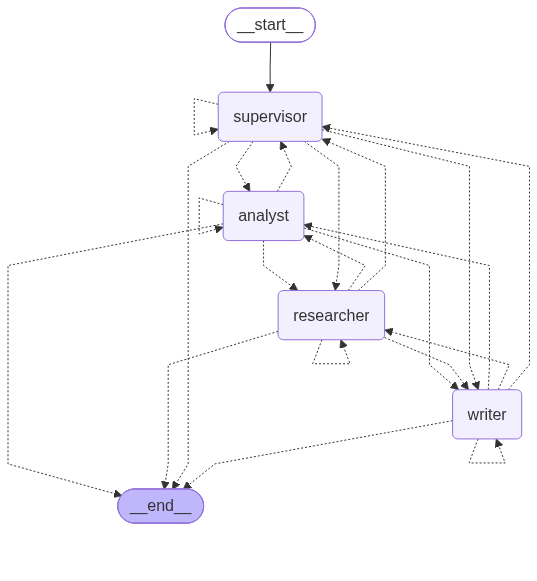

In [63]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [64]:
result = app.invoke({
    "messages": [
        HumanMessage(content="Research AI in education")
    ]
})

print(result["final_report"])

researcher
analyst
writer

    FINAL REPORT

    Generated: 2026-10-12 21:41
    Topic: Analyst: I've completed the analysis.

Top insights:
Based on the research data provided, here is a structured analysis focusing on actionable insights for stakeholders in the education sector (institutional leaders, educators, and ed-tech developers).

### 1. Key Insights and Patterns

*   **Shift from Static to Dynamic Personalization:**
    The data highlights a fundamental paradigm shift from **rule-based systems** (static diagnostic tests) to * ...
    # Executive Report: The Strategic Integration of Artificial Intelligence in Education

**Date:** October 26, 2023
**Subject:** Analysis of AI Trends and Implications for Educational Stakeholders
**Prepared For:** Institutional Leaders, Educators, and Ed-Tech Developers

## 1. Executive Summary

This report analyzes the current landscape of Artificial Intelligence (AI) in education, highlighting its rapid transition from experimental pilot program

In [44]:
import traceback

try:
    result = app.invoke({
        "messages": [
            HumanMessage(content="Research AI in education")
        ]
    })
except Exception:
    traceback.print_exc()

researcher


Traceback (most recent call last):
  File "C:\Users\M16\AppData\Local\Temp\ipykernel_5060\795014552.py", line 4, in <module>
    result = app.invoke({
             ^^^^^^^^^^^^
  File "c:\Users\M16\Desktop\ai-septembre\langgraphV1\.venv\Lib\site-packages\langgraph\pregel\main.py", line 3913, in invoke
    for chunk in self.stream(
  File "c:\Users\M16\Desktop\ai-septembre\langgraphV1\.venv\Lib\site-packages\langgraph\pregel\main.py", line 2967, in stream
    for _ in runner.tick(
  File "c:\Users\M16\Desktop\ai-septembre\langgraphV1\.venv\Lib\site-packages\langgraph\pregel\_runner.py", line 207, in tick
    run_with_retry(
  File "c:\Users\M16\Desktop\ai-septembre\langgraphV1\.venv\Lib\site-packages\langgraph\pregel\_retry.py", line 617, in run_with_retry
    return task.proc.invoke(task.input, config)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\M16\Desktop\ai-septembre\langgraphV1\.venv\Lib\site-packages\langgraph\_internal\_runnable.py", line 707, in invoke
    i